<a href="https://colab.research.google.com/github/bungei53/retail-sales-analysis-kenya/blob/main/01_eda_visualization_simple_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Retail Sales Analysis 2025: EDA and Visualization

In this notebook I explore the cleaned sales data and make charts to answer business questions.

**EDA** (Exploratory Data Analysis) means getting to know the data first: its size, its typical values, and how the columns relate.
**Visualization** means turning the numbers into charts so patterns are easy to see.

**Every chart follows the same 3 steps:**
1. **Group** the data (`groupby`)
2. **Add up or average** a column (`sum()` or `mean()`)
3. **Plot** the result (`.plot()`)

**Contents**
1. Setup and loading
2. EDA
3. Visualization
4. Key findings

## 1. Setup and Loading the Data

Connect Google Drive so the notebook can read the clean file.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Import the libraries. `pandas` handles tables, `matplotlib` and `seaborn` make charts.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")     # gives every chart a clean look

Load the clean file. `parse_dates` makes sure `order_date` is read as a real date.

In [3]:
df = pd.read_csv('/content/drive/MyDrive/sales_data_clean.csv', parse_dates=['order_date'])
df.head()

,order_id,order_date,customer_id,customer_age,region,city,product,category,quantity,unit_price,discount,payment_method,sales_channel,sales_rep,customer_rating,total_amount,month,month_name,quarter,age_was_missing
0,ORD-4701,2025-11-27,C566,39.0,Coast,Mombasa,Smartphone,Electronics,2.0,497.07,0.2,M-Pesa,Wholesale,David Kamau,4.0,795.31,11.0,Nov,4.0,False
1,ORD-2763,2025-07-18,C1043,36.0,Western,Kakamega,Bookshelf,Furniture,1.0,119.84,0.0,Cash,Wholesale,Amina Yusuf,3.0,119.84,7.0,Jul,3.0,False
2,ORD-1813,2025-11-15,C917,36.0,Rift Valley,Eldoret,T-Shirt,Apparel,1.0,18.19,0.0,M-Pesa,Wholesale,Carol Wanjiru,5.0,18.19,11.0,Nov,4.0,False
3,ORD-5136,2025-02-19,C708,60.0,Nairobi,Nairobi,Desk,Furniture,1.0,263.01,0.1,M-Pesa,Wholesale,Carol Wanjiru,5.0,236.71,2.0,Feb,1.0,False
4,ORD-4763,2025-11-22,C613,36.0,Coast,Malindi,Pen Set,Stationery,5.0,7.62,0.0,Bank Transfer,Online,David Kamau,5.0,38.10,11.0,Nov,4.0,False


## 2. Exploratory Data Analysis (EDA)

### 2.1 Size and column types
How many rows and columns, and what type is each column?

In [4]:
print("Rows and columns:", df.shape)
df.info()

Rows and columns: (5000, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         5000 non-null   object        
 1   order_date       4979 non-null   datetime64[ns]
 2   customer_id      5000 non-null   object        
 3   customer_age     5000 non-null   float64       
 4   region           5000 non-null   object        
 5   city             5000 non-null   object        
 6   product          5000 non-null   object        
 7   category         5000 non-null   object        
 8   quantity         4999 non-null   float64       
 9   unit_price       5000 non-null   float64       
 10  discount         5000 non-null   float64       
 11  payment_method   5000 non-null   object        
 12  sales_channel    5000 non-null   object        
 13  sales_rep        5000 non-null   object        
 14  customer_ra

### 2.2 Summary statistics
`describe()` shows the typical values of each number column: the average (mean), the middle (50%), the smallest (min) and the largest (max).

In [5]:
df[['customer_age', 'quantity', 'unit_price', 'discount', 'customer_rating', 'total_amount']].describe().round(2)

,customer_age,quantity,unit_price,discount,customer_rating,total_amount
count,5000.00,4999.00,5000.00,5000.00,4518.00,5000.00
mean,35.62,2.68,185.55,0.07,3.63,456.08
std,10.66,2.05,245.82,0.07,1.26,815.41
min,18.00,1.00,-5.23,0.00,1.00,2.30
25%,28.00,1.00,17.20,0.00,3.00,34.34
50%,35.00,2.00,93.86,0.05,4.00,163.38
75%,42.00,3.00,248.49,0.15,5.00,483.47
max,75.00,10.00,892.33,0.20,5.00,8817.20


**Observation:** the average order value (`total_amount` mean) is higher than the middle value (50%). This means a few very large orders pull the average up.

### 2.3 Missing values
Which columns still have blanks? Ratings and some dates were left blank on purpose during cleaning.

In [6]:
missing = df.isnull().sum()
missing[missing > 0]

,0
order_date,21
quantity,1
customer_rating,482
month,21
month_name,21
quarter,21


### 2.4 Categories
How are the orders split across regions, categories, channels and payment methods?

In [7]:
print(df['region'].value_counts(), "\n")
print(df['category'].value_counts(), "\n")
print(df['sales_channel'].value_counts(), "\n")
print(df['payment_method'].value_counts())

region
Coast          1264
Rift Valley    1256
Nairobi        1254
Western        1226
Name: count, dtype: int64 

category
Electronics    1292
Apparel        1255
Furniture      1232
Stationery     1221
Name: count, dtype: int64 

sales_channel
Online          1741
Retail Store    1667
Wholesale       1592
Name: count, dtype: int64 

payment_method
M-Pesa           1288
Bank Transfer    1279
Cash             1155
Credit Card      1153
Unknown           125
Name: count, dtype: int64


### 2.5 Distributions
How are the values spread out? A histogram shows how many orders fall in each range.

**Customer age** (ages that were filled in during cleaning are left out)

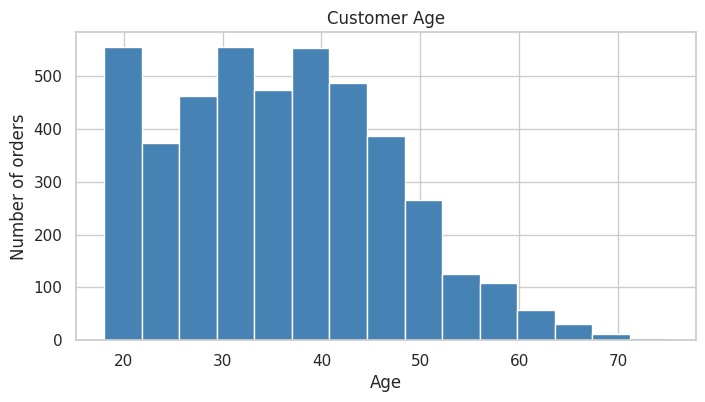

In [8]:
known_age = df[~df['age_was_missing']]

known_age['customer_age'].plot(kind='hist', bins=15, color='steelblue', edgecolor='white', figsize=(8, 4))
plt.title('Customer Age')
plt.xlabel('Age')
plt.ylabel('Number of orders')
plt.show()

**Customer rating**

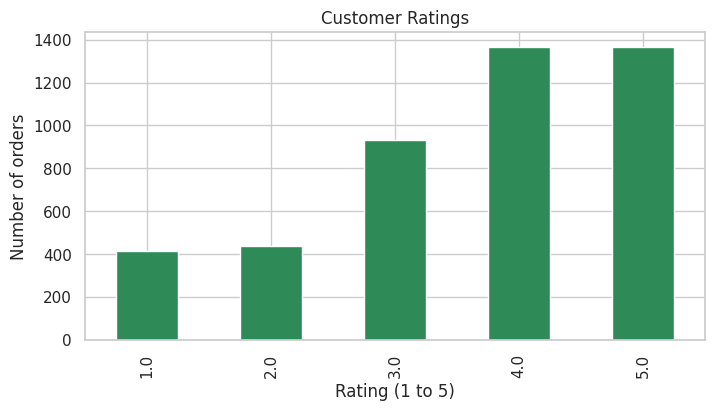

In [9]:
df['customer_rating'].value_counts().sort_index().plot(kind='bar', color='seagreen', figsize=(8, 4))
plt.title('Customer Ratings')
plt.xlabel('Rating (1 to 5)')
plt.ylabel('Number of orders')
plt.show()

**Order value** (many small orders and a few very large ones)

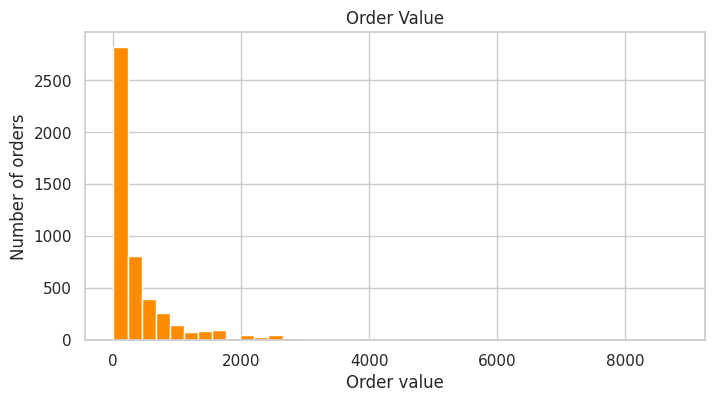

In [10]:
df['total_amount'].plot(kind='hist', bins=40, color='darkorange', edgecolor='white', figsize=(8, 4))
plt.title('Order Value')
plt.xlabel('Order value')
plt.ylabel('Number of orders')
plt.show()

**Units per order**

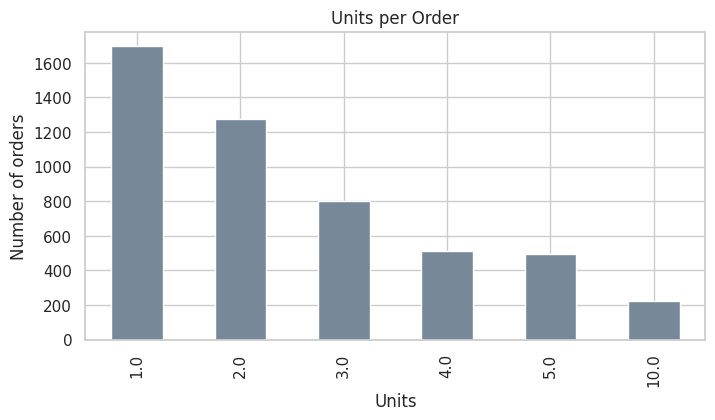

In [11]:
df['quantity'].value_counts().sort_index().plot(kind='bar', color='LightSlateGray', figsize=(8, 4))
plt.title('Units per Order')
plt.xlabel('Units')
plt.ylabel('Number of orders')
plt.show()

### 2.6 Relationships between numbers
A correlation close to **+1** means two columns rise together. Close to **0** means they are unrelated. Close to **-1** means one rises while the other falls.

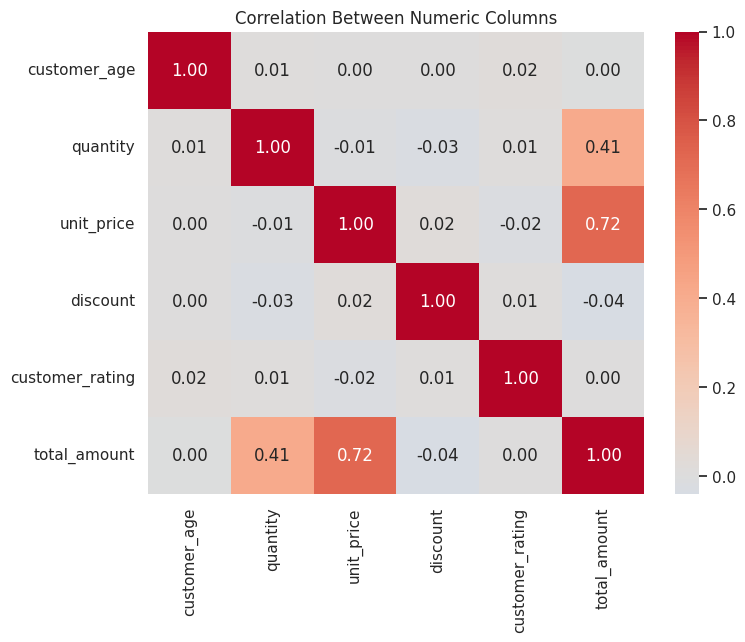

In [12]:
numbers = df[['customer_age', 'quantity', 'unit_price', 'discount', 'customer_rating', 'total_amount']]

plt.figure(figsize=(8, 6))
sns.heatmap(numbers.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title('Correlation Between Numeric Columns')
plt.show()

**Observation:** `total_amount` is related to `unit_price` and `quantity` (bigger price or more units means a bigger order). Most other columns are unrelated to each other.

## 3. Visualization
Each chart answers one business question.

### 3.1 Key numbers

In [13]:
print("Total revenue:       ", round(df['total_amount'].sum()))
print("Number of orders:    ", df['order_id'].nunique())
print("Average order value: ", round(df['total_amount'].mean()))
print("Unique customers:    ", df[df['customer_id'] != 'Unknown']['customer_id'].nunique())
print("Average rating:      ", round(df['customer_rating'].mean(), 2))

Total revenue:        2280383
Number of orders:     5000
Average order value:  456
Unique customers:     1366
Average rating:       3.63


### 3.2 Revenue by month
**Question:** when do we sell the most? (1 = January, 12 = December. The 21 orders without a valid date are left out automatically.)

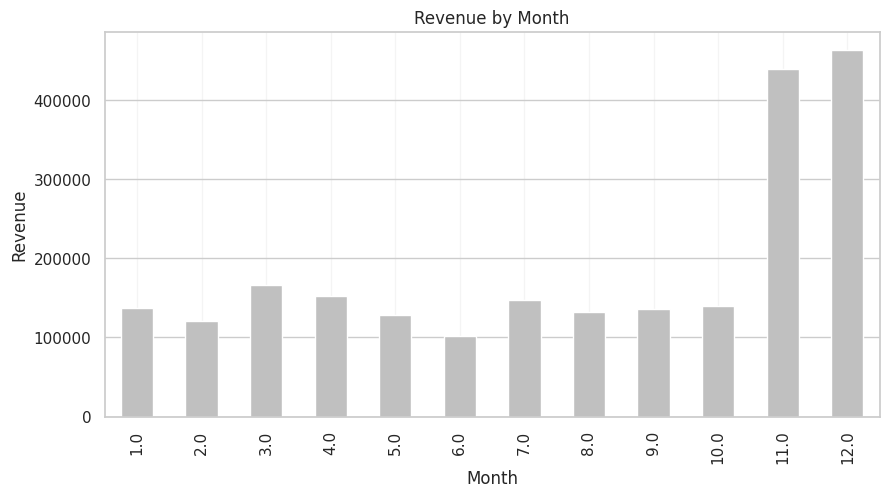

In [14]:
monthly = df.groupby(df['order_date'].dt.month)['total_amount'].sum()

monthly.plot(kind='bar', color='silver', figsize=(10, 5))
plt.title('Revenue by Month')
plt.grid(axis='x',alpha=0.2)
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.show()

### 3.3 Revenue by quarter
**Question:** how big is the holiday quarter (Q4) compared with the others?

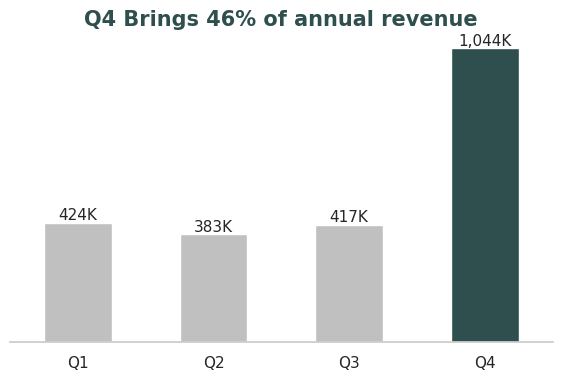

Q4 share of revenue: 46 %


In [60]:
quarterly = df.groupby('quarter')['total_amount'].sum()

# Rename 1.0, 2.0, 3.0, 4.0 to Q1, Q2, Q3, Q4
quarterly.index = 'Q' + quarterly.index.astype(int).astype(str)

# Q4 share of revenue
q4_share = quarterly['Q4'] / quarterly.sum()

# Highlight the largest quarter in dark grey, the others in silver
colors = ['darkslategrey' if value == quarterly.max() else 'silver' for value in quarterly]

# Draw the chart
ax = quarterly.plot(kind='bar', color=colors, figsize=(7, 4))
ax.bar_label(ax.containers[0], labels=[f"{v/1000:,.0f}K" for v in quarterly], fontsize=11)
ax.yaxis.set_visible(False)                    # hide the y axis and its values
plt.grid(False)                                # remove grid lines
sns.despine(left=True)                         # remove the left line

plt.title(f"Q4 Brings {q4_share:.0%} of annual revenue", color='darkslategrey',fontweight='bold',fontsize=15)
plt.xlabel('')
plt.xticks(rotation=0)
plt.show()

print("Q4 share of revenue:", round(q4_share * 100), "%")

### 3.4 Revenue by category
**Question:** which product category earns the most?

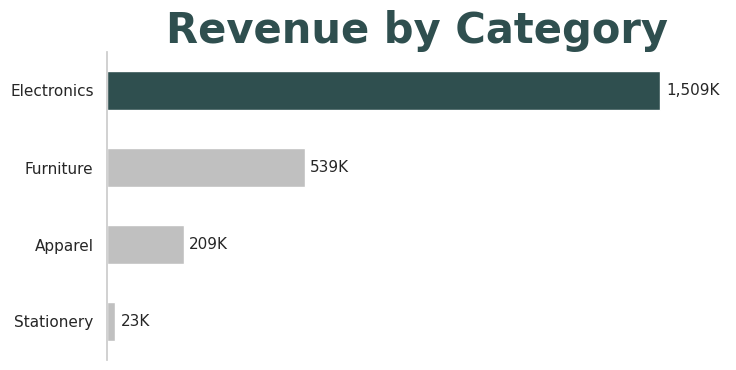

In [54]:
by_category = df.groupby('category')['total_amount'].sum().sort_values()

# Highlight the largest category in dark grey, the others in silver
colors = ['darkslategrey' if value == by_category.max() else 'silver'
          for value in by_category]

# Draw the chart
ax = by_category.plot(kind='barh', color=colors, figsize=(8, 4))
ax.bar_label(ax.containers[0], labels=[f"{v/1000:,.0f}K" for v in by_category], fontsize=11, padding=4)
ax.set_xlim(0, by_category.max() * 1.12)       # leaves room so the biggest label isn't cut off
ax.xaxis.set_visible(False)                    # hide the x axis and its values
plt.grid(False)                                # remove grid lines
sns.despine(bottom=True)                       # remove the bottom line

plt.title('Revenue by Category', color='darkslategrey',fontweight='bold',fontsize=30)
plt.ylabel('')
plt.show()

### 3.5 Revenue by region
**Question:** which region earns the most?

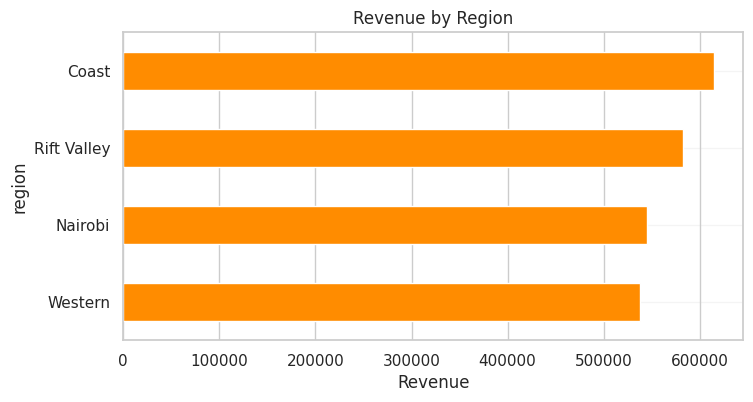

In [17]:
by_region = df.groupby('region')['total_amount'].sum().sort_values()

by_region.plot(kind='barh', color='darkorange', figsize=(8, 4))
plt.grid(axis='y',alpha=0.2)
plt.title('Revenue by Region')
plt.xlabel('Revenue')
plt.show()

### 3.6 Region and category together
**Question:** which region and category combination is strongest? Darker colour means more revenue.

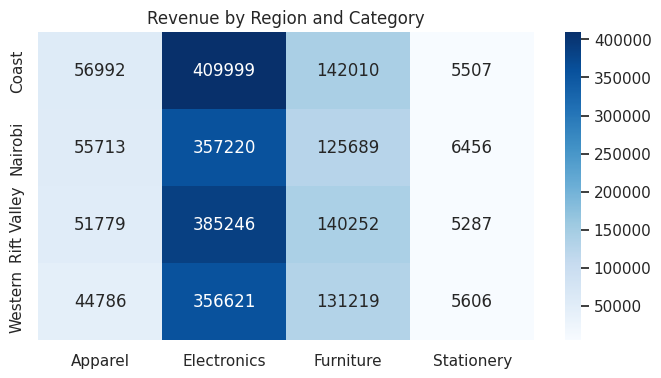

In [18]:
table = df.pivot_table(index='region', columns='category', values='total_amount', aggfunc='sum')

plt.figure(figsize=(8, 4))
sns.heatmap(table, annot=True, fmt=".0f", cmap="Blues")
plt.title('Revenue by Region and Category')
plt.ylabel('')
plt.xlabel('')
plt.show()

### 3.7 Revenue by product
**Question:** which products earn the most?

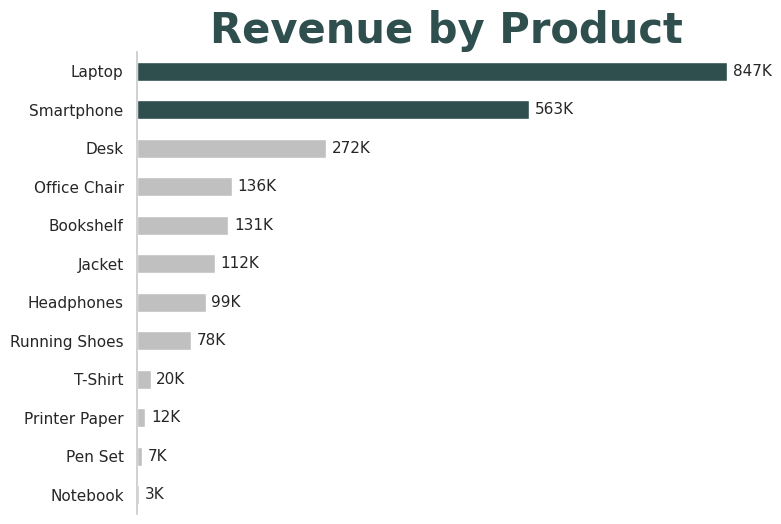

In [48]:
by_product = df.groupby('product')['total_amount'].sum().sort_values()

# The two largest products get dark grey, the others stay silver
top2 = by_product.nlargest(2).index
colors = ['darkslategrey' if product in top2 else 'silver' for product in by_product.index]

# Draw the chart
ax = by_product.plot(kind='barh', color=colors, figsize=(8, 6))
ax.bar_label(ax.containers[0], labels=[f"{v/1000:,.0f}K" for v in by_product], fontsize=11, padding=4)
ax.xaxis.set_visible(False)                    # hide the x axis and its values
plt.grid(False)                                # remove grid lines
sns.despine(bottom=True)                       # remove the bottom line

plt.title('Revenue by Product', color='darkslategrey',fontweight="bold",fontsize=30)
plt.xlabel('Revenue')
plt.ylabel('')                                 # the product names are self-explanatory
plt.show()

### 3.8 Units sold by product
**Question:** do the best-earning products also sell the most units? (Compare with the chart above.)

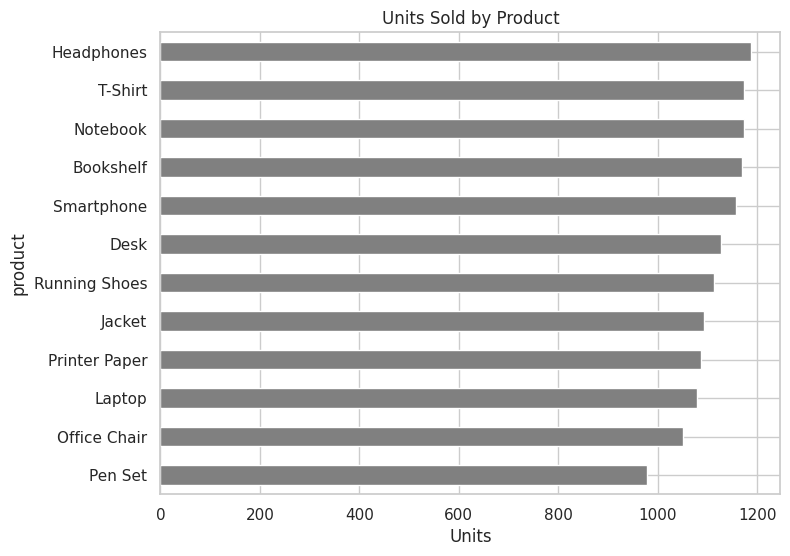

In [20]:
units_by_product = df.groupby('product')['quantity'].sum().sort_values()

units_by_product.plot(kind='barh', color='gray', figsize=(8, 6))
plt.title('Units Sold by Product')
plt.xlabel('Units')
plt.show()

**Observation:** units sold are about the same for every product, but revenue is very different. So revenue depends on the **price** of the product, not on how many are sold.

### 3.9 Sales channels
**Question:** how is revenue split between online, retail stores and wholesale?

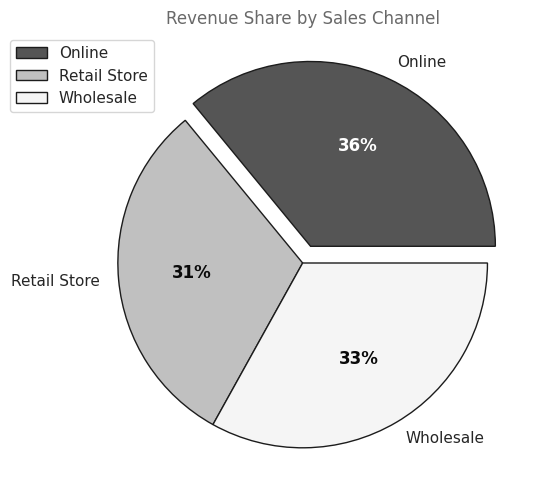

In [33]:
by_channel = df.groupby('sales_channel')['total_amount'].sum()
colors = ['#555555', '#c0c0c0', '#f5f5f5']
pct_colors = ['#ffffff', '#0a0a0a', '#0a0a0a']  # White for dark slice, black for light slices
explode = (0.1, 0, 0)
ax = by_channel.plot(
    kind='pie',
    autopct='%1.0f%%',
    figsize=(6, 6),
    explode=explode,
    colors=colors,
    wedgeprops={'edgecolor': '#1c1c1c', 'linewidth': 1}
)

# Color only the percentage labels inside the slices
for autotext, color in zip(ax.texts[1::2], pct_colors):
    autotext.set_color(color)
    autotext.set_fontweight('bold')

plt.title('Revenue Share by Sales Channel', color='dimgray')
# Position the legend explicitly in the left corner outside the pie
plt.legend(loc='upper left', bbox_to_anchor=(-0.15, 1.0))
plt.ylabel('')
plt.show()

### 3.10 Payment methods
**Question:** how do customers pay? (`Unknown` means the payment method was not recorded.)

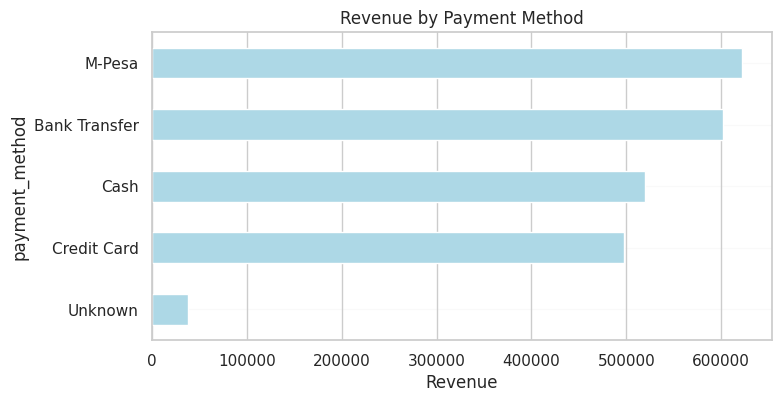

In [22]:
by_payment = df.groupby('payment_method')['total_amount'].sum().sort_values()

by_payment.plot(kind='barh', color='lightblue', figsize=(8, 4))
plt.title('Revenue by Payment Method')
plt.grid(axis='y',alpha=0.1)
plt.xlabel('Revenue')
plt.show()

### 3.11 Do discounts make people buy more?
**Question:** do customers buy more units when the discount is bigger?

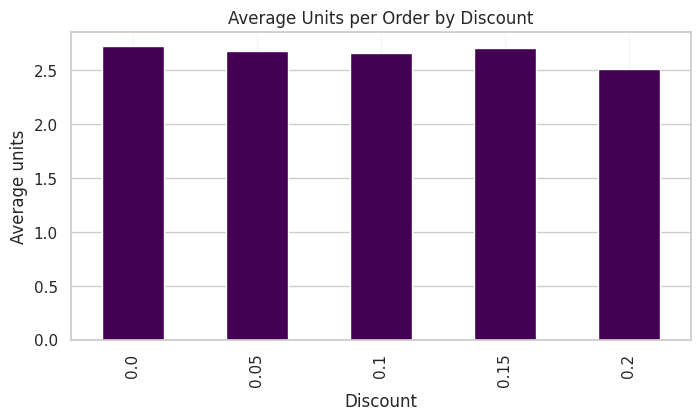

In [23]:
df.groupby('discount')['quantity'].mean().plot(kind='bar', colormap='viridis', figsize=(8, 4))
plt.title('Average Units per Order by Discount')
plt.grid(axis='x',alpha=0.2)
plt.xlabel('Discount')
plt.ylabel('Average units')
plt.show()

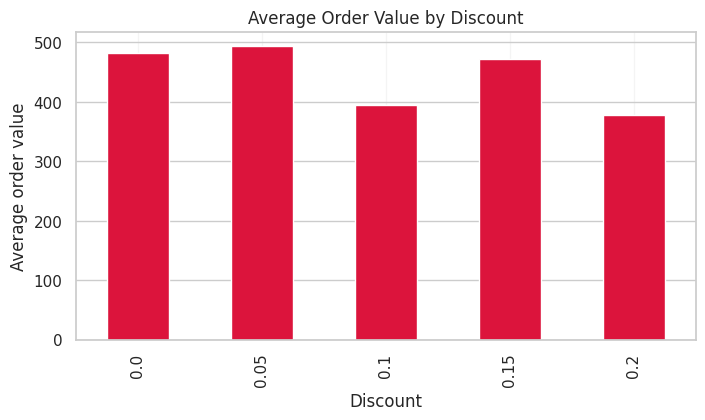

In [24]:
df.groupby('discount')['total_amount'].mean().plot(kind='bar', color='crimson', figsize=(8, 4))
plt.title('Average Order Value by Discount')
plt.xlabel('Discount')
plt.ylabel('Average order value')
plt.grid(axis='x',alpha=0.2)
plt.show()

**Observation:** the average number of units is about the same at every discount level. So bigger discounts do not make customers buy more, but they reduce the money earned per order.

### 3.12 Sales rep performance
**Question:** which sales rep earns the most revenue? (Orders with no recorded rep are left out.)

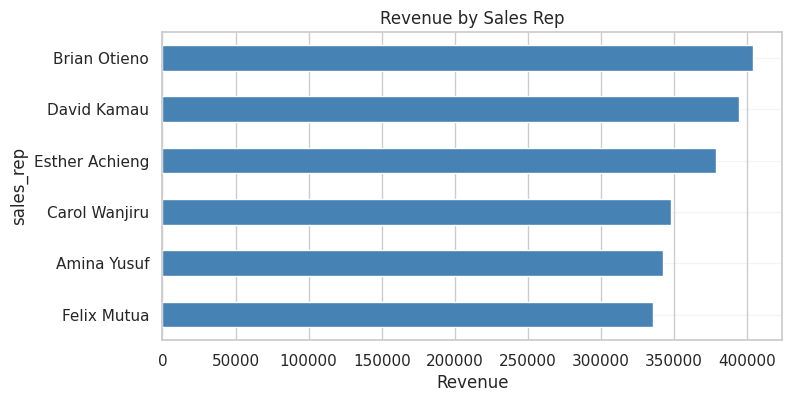

In [25]:
reps = df[df['sales_rep'] != 'Unknown']

reps.groupby('sales_rep')['total_amount'].sum().sort_values().plot(kind='barh', color='steelblue', figsize=(8, 4))
plt.title('Revenue by Sales Rep')
plt.grid(axis='y',alpha=0.2)
plt.xlabel('Revenue')
plt.show()

**Question:** do reps differ in how happy their customers are?

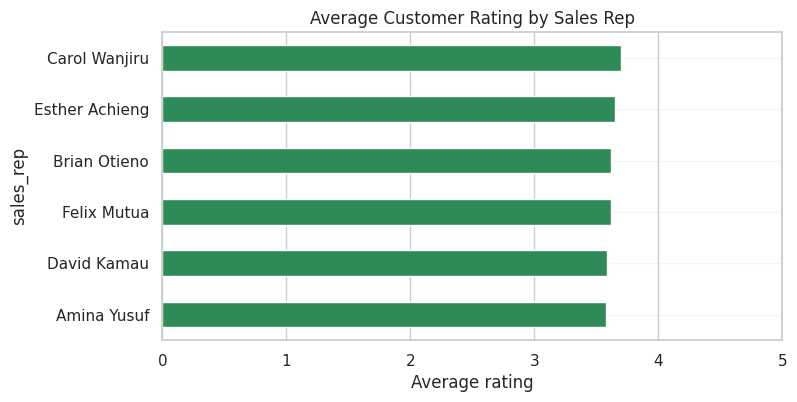

In [26]:
reps.groupby('sales_rep')['customer_rating'].mean().sort_values().plot(kind='barh', color='seagreen', figsize=(8, 4))
plt.title('Average Customer Rating by Sales Rep')
plt.xlabel('Average rating')
plt.grid(axis='y',alpha=0.2)
plt.xlim(0, 5)
plt.show()

**Observation:** the average ratings are very close (all around 3.6), so the reps do not really differ in customer satisfaction.

### 3.13 Customer satisfaction by channel
**Question:** are customers happier with one sales channel?

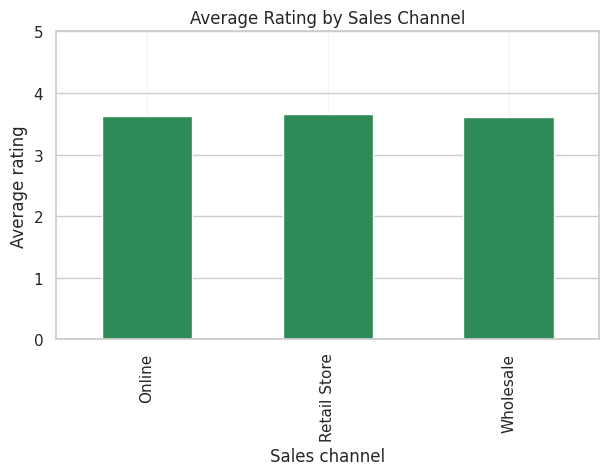

In [27]:
df.groupby('sales_channel')['customer_rating'].mean().plot(kind='bar', color='seagreen', figsize=(7, 4))
plt.title('Average Rating by Sales Channel')
plt.xlabel('Sales channel')
plt.ylabel('Average rating')
plt.grid(axis='x',alpha=0.2)
plt.ylim(0, 5)
plt.show()

### 3.14 Customer age groups
**Question:** which age groups buy the most? (Ages that were filled in during cleaning are left out.)

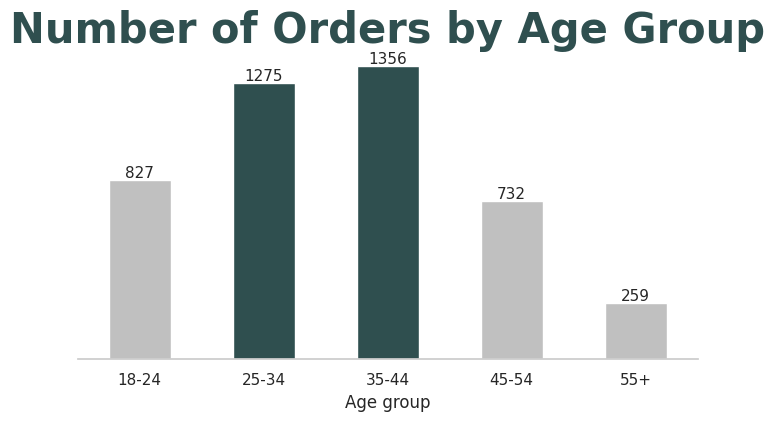

In [45]:
from matplotlib.typing import ColourType
known_age = df[~df['age_was_missing']].copy()

# Put each age into a group
known_age['age_group'] = pd.cut(known_age['customer_age'],
                                bins=[17, 24, 34, 44, 54, 75],
                                labels=['18-24', '25-34', '35-44', '45-54', '55+'])

# Count the orders in each age group
counts = known_age['age_group'].value_counts().sort_index()

# The two largest groups get dark slate grey, the others silver
top2 = counts.nlargest(2).index
colors = ['darkslategrey' if group in top2 else 'silver' for group in counts.index]

# Draw the chart
ax = counts.plot(kind='bar', color=colors, figsize=(8, 4))
ax.bar_label(ax.containers[0], fontsize=11)    # numbers on top of the bars
ax.yaxis.set_visible(False)                    # hide the y axis and its values
plt.grid(False)                                # remove grid lines
sns.despine(left=True)                         # remove the left line

plt.title('Number of Orders by Age Group',color='darkslategrey',fontweight="bold",fontsize=30)
plt.xlabel('Age group')
plt.xticks(rotation=0)                         # keep the age labels horizontal
plt.show()

## 4. Key Findings
These numbers are calculated from the data.

In [29]:
total = df['total_amount'].sum()

print("1. Total revenue:", round(total))
print("2. Best month:", int(df.groupby(df['order_date'].dt.month)['total_amount'].sum().idxmax()), "(12 = December)")
print("3. Top category:", df.groupby('category')['total_amount'].sum().idxmax())
print("4. Top region:", df.groupby('region')['total_amount'].sum().idxmax())
print("5. Top product:", df.groupby('product')['total_amount'].sum().idxmax())
print("6. Top channel:", df.groupby('sales_channel')['total_amount'].sum().idxmax())
print("7. Top sales rep:", reps.groupby('sales_rep')['total_amount'].sum().idxmax())
print("8. Correlation between discount and units:", round(df['discount'].corr(df['quantity']), 2))

1. Total revenue: 2280383
2. Best month: 12 (12 = December)
3. Top category: Electronics
4. Top region: Coast
5. Top product: Laptop
6. Top channel: Online
7. Top sales rep: Brian Otieno
8. Correlation between discount and units: -0.03




### Limitations
The data is synthetic. Some values were estimated during cleaning (ages, prices), and some ratings and dates are missing, so conclusions about those fields should be read with care.